In [1]:
"""
Trimmed Correlation Matrix -- curated indices vs. physical variables
================================================================================
A trimmed, masked version of Fig 2 from cross_comparison_sea_ice_climate_
indices.ipynb (the FULL SQUARE nh/greenland + climate indices + added
variables matrix -- source of correlation_matrix_added_vars_10yr_alt.png),
restricted to a curated variable list, with the redundant upper triangle
masked and the colorbar dropped (values are annotated in-cell), across the
same four bands used in compute_spatial_correlations.ipynb.

DATA LOADING is reused directly from cross_comparison_sea_ice_climate_
indices.ipynb Sections 1/1c/1d (confirmed file paths, confirmed
CLIM_WINTER_MONTHS=[12,1,2,3] season convention, confirmed ICE_METRIC=
'annual_max' from daily OSISAF data) -- NOT re-derived, so the underlying
numbers match that notebook's own values exactly (same variable, same band
-> same r). One addition: GGI (compute_ggi_index.ipynb's output), added the
same way CAO_index_early/late are -- loaded from its own CSV and folded
into series_dict.

STATISTICAL METHOD matches the source notebook's Fig 2 exactly: plain
Pearson r/p (scipy.stats.pearsonr) on Butterworth band-pass filtered ANNUAL
series (fs=1 yr^-1, order 4, reflection-padded) -- NOT the Ebisuzaki
surrogate approach used in compute_eof_correlation_timescales.ipynb, which
is specific to that notebook's EOF work. Matching methodology here, not
methodology from a different notebook, is what keeps these numbers directly
comparable to the original matrix image.

BANDS: the same four from compute_spatial_correlations.ipynb -- unfiltered,
2.5-6yr, 7-13yr, 15-25yr (see that notebook's discussion with Chris for why
these four, and why 2yr had to move to 2.5yr -- Nyquist limit at annual
resolution).

TRIMMED VARIABLE LIST (curated with Chris)
  Indices  (rows/cols 1-9):  GBI_UL, GGI, NAO, AO, PDO, TPQD, SCAND, AD,
                             NINO34
                             (SCAND added 2026-09; not in all_climate_
                             indices.nc, loaded from the raw CPC file --
                             see load_scand_raw() in Section 1b. AD added
                             2026-09; already in all_climate_indices.nc,
                             no raw loader needed.)
  Physical (rows/cols 9+):   nh, greenland, CAO_index_early, CAO_index_late,
                             GS_u10, GS_v10, Runoff_NE, UpperOcean_temp,
                             UpperOcean_sal, PSW_temp, PSW_sal, PSW_flux,
                             PSW_thickness, AW_temp, AW_sal, AW_flux
  Same ordered list on BOTH axes (square matrix) -- indices first, then
  physical variables -- matching how "y axis: indices, x axis: physical
  variables" was described: reading order, not two disjoint axes. Upper
  triangle masked (diagonal visible) since every value below it is a
  mirror-image repeat.

Outputs
-------
  ./outputs/processed_data/trimmed_correlation_matrix/{band_tag}/correlation_matrix.csv
  ./outputs/processed_data/trimmed_correlation_matrix/{band_tag}/correlation_pvalues.csv
  ./outputs/processed_data/trimmed_correlation_matrix/{band_tag}/correlation_pvalues_neff.csv       (1.4.0)
  ./outputs/processed_data/trimmed_correlation_matrix/{band_tag}/effective_n.csv                   (1.4.0)
  ./outputs/processed_data/trimmed_correlation_matrix/{band_tag}/correlation_pvalues_surrogate.csv (1.4.0)
  ./outputs/processed_data/trimmed_correlation_matrix/corrected_pvalue_comparison.csv              (1.4.0)
  ./outputs/figures/trimmed_correlation_matrix/{band_tag}/trimmed_correlation_matrix.png
  ./outputs/methods/trimmed_correlation_matrix_methodology.md
  ./outputs/methods/trimmed_correlation_matrix_corrected_pvalues_methodology.md                    (1.4.0)

Version:       1.4.0
Last Modified: 2026-10-01

CHANGE (1.4.0): added autocorrelation-corrected significance (Section 3b),
written to NEW per-band files alongside the originals -- the plain-Pearson
correlation_pvalues.csv and correlation_matrix.csv are produced exactly as
before and never overwritten, so downstream figures can use either scheme.
Two corrections: (i) effective-sample-size t-test, N_eff from the full-lag
Bartlett/Quenouille sum (effective_n.csv saved too); (ii) Ebisuzaki (1997)
phase-randomised surrogates, generated from the RAW series and passed
through the identical Butterworth filter, so the test accounts for the
filter exactly. r values are unchanged and asserted identical.

CHANGE (1.3.0): added AD (Arctic Dipole, EOF2 of ERA5 MSLP poleward of
70N, sign-fixed to Wu et al. 2006's Canada-high/Siberia-low convention --
see compute_arctic_dipole.ipynb) to TRIMMED_INDICES. Unlike SCAND/NINO34,
AD is already written into all_climate_indices.nc directly, so it needs
no raw-file loader of its own -- it's picked up automatically by the
existing climate_var_names loop in Section 1, the same way GBI_UL/NAO/
AO/PDO/TPQD already are.

CHANGE (1.2.0): added NINO34 to TRIMMED_INDICES, same pattern as SCAND
(1.1.0) -- raw CPC file, loaded via load_nino34_raw() in Section 1b,
folded into series_dict via the identical assign_season_year +
groupby-mean pattern as every other variable. No change to season
convention, filtering, or statistics for the seven pre-existing indices.

CHANGE (1.1.0): added SCAND to TRIMMED_INDICES. Not present in
all_climate_indices.nc; loaded from the raw CPC file directly
(load_scand_raw() in Section 1b), same PSL 'YEAR v1..v12' whitespace
format already parsed elsewhere in the project. Folded into series_dict
via the identical assign_season_year + groupby-mean pattern as every
other variable here -- no change to season convention, filtering, or
statistics for the six pre-existing indices.
Author:        C. Barrell
"""

import sys
import logging
import warnings
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats, signal

warnings.filterwarnings("ignore")

sys.path.append('..')
try:
    from utils.logger import get_logger
    logger = get_logger(__name__, config_path='../config.yaml')
except Exception:
    logger = logging.getLogger(__name__)
    logging.basicConfig(level=logging.INFO, format='%(asctime)s | %(levelname)-7s | %(message)s')

# ============================================================================
# CONFIGURATION
# ============================================================================

SAVE_DATA = True

# --- Source files (SAME as cross_comparison_sea_ice_climate_indices.ipynb) ---
CLIMATE_NC = Path('./outputs/processed_data/climate_indices/all_climate_indices.nc')
OSISAF_NC  = Path('./outputs/processed_data/osisaf_sii_v3/osisaf_sii_v3_all_regions.nc')
GGI_CSV    = Path('./outputs/processed_data/climate_indices/GGI_monthly.csv')
# SCAND is not in all_climate_indices.nc (confirmed absent -- see the
# trimmed-matrix output Chris reviewed, which lists GBI_UL/GGI/NAO/AO/PDO/
# TPQD as the only index-side variables present). Source is the raw CPC
# file, same 'YEAR v1..v12' whitespace format the project's other raw-file
# readers already parse (figure_index_phases.ipynb's read_psl_data).
SCAND_RAW  = Path('/local/jbj13rpu/Documents/ROVER/climate_indices/raw/SCAND.data')
# NINO3.4 -- same situation as SCAND: not in all_climate_indices.nc, raw
# CPC file, same PSL 'YEAR v1..v12' format. Missing-value sentinel here is
# -99.99 (SST fill value), not SCAND's -99.9.
NINO34_RAW = Path('/local/jbj13rpu/Documents/ROVER/climate_indices/raw/NINO34.data')

FIGURE_04_DIR = Path('./outputs/processed_data/figure_04/')
FIGURE_05_DIR = Path('./outputs/processed_data/figure_05/')
UPPER_OCEAN_DIR = Path('./outputs/processed_data/glorys12_upper_ocean/')
FRESHWATER_DIR = Path('./outputs/processed_data/fig_greenland_freshwater_inputs/')
FRAM_ICE_DIR = Path('./outputs/processed_data/glorys12_fram_strait_ice/')
ERA5_WIND_DIR = Path('./outputs/processed_data/era5_gs_winds/')
CAO_EARLY_CSV = Path('./outputs/processed_data/figure_06/cao_index_early.csv')
CAO_LATE_CSV  = Path('./outputs/processed_data/figure_06/cao_index_late.csv')

PSW_S_THRESHOLD = 34.5
PSW_RHO_THRESHOLD = 1027.7
PSW_PROPS_CSV = FIGURE_04_DIR / f'psw_properties_S{PSW_S_THRESHOLD}_rho{PSW_RHO_THRESHOLD}.csv'
PSW_FLUX_CSV  = FIGURE_04_DIR / f'psw_flux_S{PSW_S_THRESHOLD}_rho{PSW_RHO_THRESHOLD}.csv'
PSW_TS_CSV    = FIGURE_05_DIR / 'psw_timeseries_monthly.csv'
UPPER_OCEAN_TS_CSV = UPPER_OCEAN_DIR / 'upper_ocean_0_50m_TS_monthly.csv'
RUNOFF_NE_CSV = FRESHWATER_DIR / 'runoff_monthly_NE.csv'
ERA5_WIND_CSV = ERA5_WIND_DIR / 'gs_10m_winds_monthly.csv'

# --- Season convention (SAME as the source notebook -- NOT this project's
# usual WINTER_MONTHS=[10..4]; matching the ORIGINAL matrix's own definition
# is what keeps these numbers comparable to it) ---
CLIM_WINTER_MONTHS = [12, 1, 2, 3]   # Dec-Mar mean -- OCEAN VARIABLES ONLY as
                                     # of INDEX_SEASON below (was also used for
                                     # indices; kept fixed at DJFM here for
                                     # ocean vars regardless of INDEX_SEASON)

# Season convention for the CLIMATE INDICES specifically (GBI, NAO, AO, PDO,
# TPQD, SCAND, NINO3.4) -- separate from CLIM_WINTER_MONTHS above, which
# still governs the ocean variables (PSW/AW flux, upper-ocean T/S, runoff,
# GS winds) unconditionally. Chris wants to try ONDJFMA for the indices
# specifically, for consistency with the unfiltered-monthly panel's
# convention -- NOT for the ocean variables, so those two are now decoupled
# rather than sharing one constant.
#   'DJFM'    -- [12,1,2,3], the original/default, matches ocean vars
#   'ONDJFMA' -- [10,11,12,1,2,3,4], full winter, matches the unfiltered panel
INDEX_SEASON = 'ONDJFMA'   # 'DJFM' | 'ONDJFMA'
if INDEX_SEASON not in ('DJFM', 'ONDJFMA'):
    raise ValueError(f"INDEX_SEASON must be 'DJFM' or 'ONDJFMA', got {INDEX_SEASON!r}")
INDEX_WINTER_MONTHS = CLIM_WINTER_MONTHS if INDEX_SEASON == 'DJFM' else [10, 11, 12, 1, 2, 3, 4]

# NOTE: GGI is loaded through the SAME code path as the ocean variables
# (ocean_series_specs in Section 1c) and so stays on CLIM_WINTER_MONTHS
# (DJFM) regardless of INDEX_SEASON, even though it's conceptually an
# index. Not currently plotted in the combined figure (dropped as
# redundant with GBI), so left as-is rather than restructured to split it
# out -- flag this if GGI is ever reinstated while INDEX_SEASON='ONDJFMA'
# is in use, since its season convention would then be inconsistent with
# the other indices.
ICE_METRIC = 'annual_max'             # true annual max from daily OSISAF data

# --- Bands (SAME as compute_spatial_correlations.ipynb) ---
BANDS = [
    ('unfiltered', None),
    ('interannual_2.5-6yr', (2.5, 6)),
    ('QD_7-13yr', (7, 13)),
    ('multidecadal_15-25yr', (15, 25)),
]
BUTTER_ORDER = 4
ALPHA = 0.05

# --- Corrected significance (1.4.0, Section 3b) ---
# Plain Pearson p (correlation_pvalues.csv) assumes independent years,
# which band-pass filtering strongly violates (~4-6 independent cycles in
# 7-13yr at annual resolution). Both corrections below are written to
# separate files; the plain p-values are still produced unchanged.
COMPUTE_CORRECTED_P = True
N_SURROGATES = 1000        # phase-randomised surrogates per variable per band
SURROGATE_SEED = 42        # combined with (band index, variable position) per variable
NEFF_MAX_LAG_FRAC = 0.25   # sum autocorrelation products to lag floor(0.25 * N)
NEFF_MIN = 3.0             # floor on N_eff (t-test needs N_eff - 2 > 0)
# Cells summarised in the methods output / comparison CSV -- the Figure 8
# panel (a) targets; does not affect what is computed or saved.
SUMMARY_TARGETS = ['greenland', 'CAO_index_early', 'CAO_index_late']

# --- Trimmed variable list (curated with Chris) ---
TRIMMED_INDICES = ['GBI_UL', 'GGI', 'NAO', 'AO', 'PDO', 'TPQD', 'SCAND', 'AD', 'NINO34']   # EA dropped per Chris
TRIMMED_PHYSICAL = ['nh', 'greenland', 'CAO_index_early', 'CAO_index_late',
                    'GS_u10', 'GS_v10', 'Runoff_NE', 'UpperOcean_temp', 'UpperOcean_sal',
                    'PSW_temp', 'PSW_sal', 'PSW_flux', 'PSW_thickness',
                    'AW_temp', 'AW_sal', 'AW_flux']
TRIMMED_VARS = TRIMMED_INDICES + TRIMMED_PHYSICAL

DISPLAY_NAMES = {'GBI_UL': 'GBI', 'nh': 'NH ice', 'greenland': 'Greenland ice'}
def dname(x):
    return DISPLAY_NAMES.get(x, x)

# --- Output dirs ---
OUT_FIG_ROOT  = Path('./outputs/figures/trimmed_correlation_matrix')
OUT_DATA_ROOT = Path('./outputs/processed_data/trimmed_correlation_matrix')
# Suffix only applied for the non-default index season, so INDEX_SEASON=
# 'DJFM' (the default) writes to the EXACT SAME paths as before -- existing
# DJFM-based outputs are never at risk of being overwritten by this cell.
if INDEX_SEASON == 'ONDJFMA':
    OUT_FIG_ROOT = OUT_FIG_ROOT.parent / f'{OUT_FIG_ROOT.name}_indexONDJFMA'
    OUT_DATA_ROOT = OUT_DATA_ROOT.parent / f'{OUT_DATA_ROOT.name}_indexONDJFMA'
OUT_METH = Path('./outputs/methods')
for d in (OUT_FIG_ROOT, OUT_DATA_ROOT, OUT_METH):
    d.mkdir(parents=True, exist_ok=True)
DPI = 600

logger.info(f"INDEX_SEASON={INDEX_SEASON!r} (INDEX_WINTER_MONTHS={INDEX_WINTER_MONTHS}), "
           f"CLIM_WINTER_MONTHS={CLIM_WINTER_MONTHS} (ocean vars, unchanged), "
           f"OUT_FIG_ROOT={OUT_FIG_ROOT}")

logger.info(f"TRIMMED_VARS ({len(TRIMMED_VARS)}): {TRIMMED_VARS}")
logger.info(f"BANDS: {[b[0] for b in BANDS]}")


2026-10-01 10:47:43,416 | INFO    | INDEX_SEASON='ONDJFMA' (INDEX_WINTER_MONTHS=[10, 11, 12, 1, 2, 3, 4]), CLIM_WINTER_MONTHS=[12, 1, 2, 3] (ocean vars, unchanged), OUT_FIG_ROOT=outputs/figures/trimmed_correlation_matrix_indexONDJFMA
2026-10-01 10:47:43,416 | INFO    | TRIMMED_VARS (25): ['GBI_UL', 'GGI', 'NAO', 'AO', 'PDO', 'TPQD', 'SCAND', 'AD', 'NINO34', 'nh', 'greenland', 'CAO_index_early', 'CAO_index_late', 'GS_u10', 'GS_v10', 'Runoff_NE', 'UpperOcean_temp', 'UpperOcean_sal', 'PSW_temp', 'PSW_sal', 'PSW_flux', 'PSW_thickness', 'AW_temp', 'AW_sal', 'AW_flux']
2026-10-01 10:47:43,417 | INFO    | BANDS: ['unfiltered', 'interannual_2.5-6yr', 'QD_7-13yr', 'multidecadal_15-25yr']


## Section 1 -- Load data (reused from cross_comparison_sea_ice_climate_indices.ipynb)

Same loading logic, same file paths, same season convention as that
notebook's Sections 1/1c/1d -- not re-derived. Builds `series_dict`, one
annual pandas Series per variable, keyed by name.

In [2]:
def assign_season_year(time_index, season_months):
    """'Season year' = the year the season ENDS in (project convention).
    Months Jul-Dec roll forward to year+1; Jan-Jun keep their own year."""
    years = time_index.year.values
    months = time_index.month.values
    season_year = np.where(months >= 7, years + 1, years)
    mask = np.isin(months, season_months)
    return season_year, mask


def seasonal_series(da, months, name):
    time_index = pd.DatetimeIndex(da['time'].values)
    season_year, mask = assign_season_year(time_index, months)
    if mask.sum() == 0:
        logger.warning(f"[{name}] No timestamps matched months={months}.")
    df = pd.DataFrame({'season_year': season_year[mask], 'value': da.values[mask]})
    out = df.groupby('season_year')['value'].mean()
    out.name = name
    out.index.name = 'year'
    return out


def annual_max_series(da_daily, name):
    """Annual maximum from DAILY data, plain calendar-year grouping (matches
    figure_01's convention)."""
    df = da_daily.to_dataframe(name='value').reset_index()
    time_col = 'time' if 'time' in df.columns else df.columns[0]
    df['year'] = pd.DatetimeIndex(df[time_col]).year
    if df['value'].isna().all():
        logger.warning(f"[{name}] All daily values NaN -- cannot compute annual max.")
        out = pd.Series(dtype=float, name=name)
        out.index.name = 'year'
        return out
    out = df.groupby('year')['value'].max()
    out.name = name
    out.index.name = 'year'
    return out


if not CLIMATE_NC.exists():
    raise FileNotFoundError(f"{CLIMATE_NC} not found.")
if not OSISAF_NC.exists():
    raise FileNotFoundError(f"{OSISAF_NC} not found.")

ds_clim = xr.open_dataset(CLIMATE_NC)
ds_ice  = xr.open_dataset(OSISAF_NC)

climate_var_names = list(ds_clim.data_vars)
logger.info(f"Climate indices found ({len(climate_var_names)}): {climate_var_names}")
for name in TRIMMED_INDICES:
    if name in ('GGI', 'SCAND', 'NINO34'):
        continue   # loaded separately below, not part of all_climate_indices.nc
    if name not in climate_var_names:
        logger.warning(f"[{name}] requested in TRIMMED_INDICES but NOT found in "
                       f"{CLIMATE_NC} -- will be missing from the matrix. "
                       f"Available: {climate_var_names}")

series_dict = {}
for var in climate_var_names:
    series_dict[var] = seasonal_series(ds_clim[var], INDEX_WINTER_MONTHS, var)

ice_var_names_daily = [v for v in ds_ice.data_vars if v.endswith('_daily')]
if ICE_METRIC == 'annual_max':
    if not ice_var_names_daily:
        raise ValueError("ICE_METRIC='annual_max' requires daily variables in "
                         f"{OSISAF_NC}, none found.")
    for var in ice_var_names_daily:
        region_key = var.replace('ice_extent_', '').replace('_daily', '')
        series_dict[region_key] = annual_max_series(ds_ice[var], region_key)

for name in ['nh', 'greenland']:
    if name not in series_dict:
        logger.warning(f"[{name}] requested region not found in {OSISAF_NC}. "
                       f"Available regions: "
                       f"{[v.replace('ice_extent_', '').replace('_daily', '') for v in ice_var_names_daily]}")

logger.info(f"series_dict after climate indices + ice regions: {len(series_dict)} series")


2026-10-01 10:47:45,028 | INFO    | Using ONLINE Argo Float implementation
2026-10-01 10:47:45,507 | INFO    | HTTP Request: GET https://raw.githubusercontent.com/IrishMarineInstitute/awesome-erddap/master/erddaps.json "HTTP/1.1 200 OK"
2026-10-01 10:47:46,767 | INFO    | Climate indices found (12): ['GBI_UL', 'AO', 'NAO', 'PDO', 'PNA', 'SCAND', 'NINO4', 'NINO34', 'IPO_TPI_FILT', 'IPO_TPI_UNFILT', 'TPQD', 'AD']
2026-10-01 10:47:46,887 | INFO    | series_dict after climate indices + ice regions: 32 series


## Section 1b -- Load physical variables (PSW/AW, upper ocean, runoff, wind, CAO, GGI)

Same `ocean_series_specs` pattern as the source notebook -- one CSV per
variable, candidate column names tried in order, warns and skips (rather
than failing the whole notebook) if a file or column isn't found. GGI is
the one addition, using its own CSV (`compute_ggi_index.ipynb`'s output)
but otherwise going through the exact same loader.

In [3]:
def load_ocean_csv(path, label):
    if path is None or not Path(path).exists():
        logger.warning(f"[{label}] File not found: {path} -- skipped.")
        return None
    df = pd.read_csv(path)
    time_col = 'time' if 'time' in df.columns else df.columns[0]
    df['time'] = pd.to_datetime(df[time_col])
    return df


def find_column(df, candidates, label):
    cols_lower = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in cols_lower:
            return cols_lower[cand.lower()]
    for cand in candidates:
        for col_lower, col in cols_lower.items():
            if cand.lower() in col_lower:
                return col
    logger.warning(f"[{label}] None of candidate columns {candidates} found in "
                   f"{df.columns.tolist()} -- skipped.")
    return None


ocean_series_specs = [
    (PSW_PROPS_CSV,      'PSW_temp',        ['temp', 'psw_temp', 'temperature']),
    (PSW_PROPS_CSV,      'PSW_sal',         ['sal', 'psw_sal', 'salinity']),
    (PSW_FLUX_CSV,       'PSW_flux',        ['flux', 'transport', 'psw_flux', 'psw_transport']),
    (PSW_TS_CSV,         'PSW_thickness',   ['psw_mean_thickness_m', 'thickness']),
    (UPPER_OCEAN_TS_CSV, 'UpperOcean_temp', ['temp_0_50m', 'temp', 'temperature']),
    (UPPER_OCEAN_TS_CSV, 'UpperOcean_sal',  ['sal_0_50m', 'sal', 'salinity']),
    (RUNOFF_NE_CSV,      'Runoff_NE',       ['runoff_km3_NE', 'runoff_km3']),
    (ERA5_WIND_CSV,      'GS_u10',          ['u10_mean']),
    (ERA5_WIND_CSV,      'GS_v10',          ['v10_mean']),
    (GGI_CSV,            'GGI',             ['GGI']),
]

# AW threshold values not confirmed -- glob-matched rather than hardcoded
# (same approach as the source notebook).
aw_props_matches = sorted(FIGURE_04_DIR.glob('aw_properties_*.csv')) if FIGURE_04_DIR.exists() else []
aw_flux_matches  = sorted(FIGURE_04_DIR.glob('aw_flux_*.csv')) if FIGURE_04_DIR.exists() else []
AW_PROPS_CSV = aw_props_matches[0] if aw_props_matches else None
AW_FLUX_CSV  = aw_flux_matches[0] if aw_flux_matches else None
if len(aw_props_matches) > 1:
    logger.warning(f"Multiple aw_properties_*.csv found, using first: {AW_PROPS_CSV}")
if len(aw_flux_matches) > 1:
    logger.warning(f"Multiple aw_flux_*.csv found, using first: {AW_FLUX_CSV}")
ocean_series_specs += [
    (AW_PROPS_CSV, 'AW_temp', ['temp', 'aw_temp', 'temperature']),
    (AW_PROPS_CSV, 'AW_sal',  ['sal', 'aw_sal', 'salinity']),
    (AW_FLUX_CSV,  'AW_flux', ['flux', 'transport', 'aw_flux', 'aw_transport']),
]

_ocean_csv_cache = {}
for path, name, candidates in ocean_series_specs:
    if path is None:
        logger.warning(f"[{name}] Source file not available -- skipped.")
        continue
    key = str(path)
    if key not in _ocean_csv_cache:
        _ocean_csv_cache[key] = load_ocean_csv(path, name)
    df = _ocean_csv_cache[key]
    if df is None:
        continue
    col = find_column(df, candidates, name)
    if col is None:
        continue

    time_index = pd.DatetimeIndex(df['time'])
    season_year, mask = assign_season_year(time_index, CLIM_WINTER_MONTHS)
    tmp = pd.DataFrame({'season_year': season_year[mask], 'value': df[col].values[mask]})
    s_out = tmp.groupby('season_year')['value'].mean()
    s_out.name = name
    s_out.index.name = 'year'
    series_dict[name] = s_out
    logger.info(f"[{name}] loaded from column '{col}' of {path} ({s_out.notna().sum()} valid years)")


def load_scand_raw(path, label='SCAND'):
    """SCAND is a raw CPC file (PSL 'YEAR v1..v12' whitespace format), not
    a CSV like every other single-file variable here, so it needs its own
    parser -- but is folded into series_dict via the identical
    assign_season_year + groupby-mean pattern used for everything else
    above, not a separate season-handling path. Missing-value sentinel for
    this file is -99.9 (mask any close match rather than only the exact
    literal, since CPC files sometimes carry it as -99.90 or -99.900).
    """
    if not path.exists():
        logger.warning(f"[{label}] File not found: {path} -- skipped.")
        return None
    recs = []
    for ln in path.read_text().splitlines()[1:]:   # skip the year-range header line
        parts = ln.split()
        if len(parts) != 13:
            continue   # header/footer/URL lines
        try:
            yr = int(parts[0])
            vals = [float(v) for v in parts[1:]]
        except ValueError:
            continue
        if not (1800 < yr < 2100):
            continue
        for m, v in enumerate(vals, start=1):
            recs.append((pd.Timestamp(yr, m, 1), v))
    if not recs:
        logger.warning(f"[{label}] No parseable rows in {path} -- skipped.")
        return None
    s = pd.Series(dict(recs)).sort_index()
    s = s.mask(np.isclose(s, -99.9, atol=0.01))
    df = pd.DataFrame({'time': s.index, label.lower(): s.values})
    return df


_scand_df = load_scand_raw(SCAND_RAW, 'SCAND')
if _scand_df is not None:
    time_index = pd.DatetimeIndex(_scand_df['time'])
    season_year, mask = assign_season_year(time_index, INDEX_WINTER_MONTHS)
    tmp = pd.DataFrame({'season_year': season_year[mask],
                        'value': _scand_df['scand'].values[mask]})
    s_out = tmp.groupby('season_year')['value'].mean()
    s_out.name = 'SCAND'
    s_out.index.name = 'year'
    series_dict['SCAND'] = s_out
    logger.info(f"[SCAND] loaded from {SCAND_RAW} "
               f"({s_out.notna().sum()} valid years)")


def load_nino34_raw(path, label='NINO34'):
    """NINO3.4, same raw-CPC-file situation as SCAND, but with a different
    missing-value sentinel (-99.99, the SST fill value, vs SCAND's -99.9).
    Uses np.isclose rather than exact equality for the same reason SCAND's
    parser does -- CPC files sometimes carry the sentinel at slightly
    different precision (-99.99 vs -99.990).
    """
    if not path.exists():
        logger.warning(f"[{label}] File not found: {path} -- skipped.")
        return None
    recs = []
    for ln in path.read_text().splitlines()[1:]:
        parts = ln.split()
        if len(parts) != 13:
            continue
        try:
            yr = int(parts[0])
            vals = [float(v) for v in parts[1:]]
        except ValueError:
            continue
        if not (1800 < yr < 2100):
            continue
        for m, v in enumerate(vals, start=1):
            recs.append((pd.Timestamp(yr, m, 1), v))
    if not recs:
        logger.warning(f"[{label}] No parseable rows in {path} -- skipped.")
        return None
    s = pd.Series(dict(recs)).sort_index()
    s = s.mask(np.isclose(s, -99.99, atol=0.01))
    df = pd.DataFrame({'time': s.index, label.lower(): s.values})
    return df


_nino34_df = load_nino34_raw(NINO34_RAW, 'NINO34')
if _nino34_df is not None:
    time_index = pd.DatetimeIndex(_nino34_df['time'])
    season_year, mask = assign_season_year(time_index, INDEX_WINTER_MONTHS)
    tmp = pd.DataFrame({'season_year': season_year[mask],
                        'value': _nino34_df['nino34'].values[mask]})
    s_out = tmp.groupby('season_year')['value'].mean()
    s_out.name = 'NINO34'
    s_out.index.name = 'year'
    series_dict['NINO34'] = s_out
    logger.info(f"[NINO34] loaded from {NINO34_RAW} "
               f"({s_out.notna().sum()} valid years)")


def load_annual_cao_csv(path, label):
    if not path.exists():
        logger.warning(f"[{label}] File not found: {path} -- skipped.")
        return None
    df = pd.read_csv(path)
    if 'year' not in df.columns or 'cao_index' not in df.columns:
        logger.warning(f"[{label}] Expected columns 'year'/'cao_index' not found "
                       f"(got {df.columns.tolist()}) -- skipped.")
        return None
    s = df.set_index('year')['cao_index']
    s.index.name = 'year'
    s.name = label
    return s


for label, path in [('CAO_index_early', CAO_EARLY_CSV), ('CAO_index_late', CAO_LATE_CSV)]:
    s = load_annual_cao_csv(path, label)
    if s is not None:
        series_dict[label] = s

missing = [v for v in TRIMMED_VARS if v not in series_dict]
if missing:
    logger.warning(f"TRIMMED_VARS entries not found in series_dict, will be blank "
                   f"rows/columns in the matrix: {missing}")
logger.info(f"series_dict complete: {len(series_dict)} series. "
           f"{len(TRIMMED_VARS) - len(missing)}/{len(TRIMMED_VARS)} of TRIMMED_VARS available.")


2026-10-01 10:47:46,940 | INFO    | [PSW_temp] loaded from column 'temp' of outputs/processed_data/figure_04/psw_properties_S34.5_rho1027.7.csv (34 valid years)
2026-10-01 10:47:46,943 | INFO    | [PSW_sal] loaded from column 'sal' of outputs/processed_data/figure_04/psw_properties_S34.5_rho1027.7.csv (34 valid years)
2026-10-01 10:47:46,950 | INFO    | [PSW_flux] loaded from column 'flux_sv' of outputs/processed_data/figure_04/psw_flux_S34.5_rho1027.7.csv (34 valid years)
2026-10-01 10:47:46,958 | INFO    | [PSW_thickness] loaded from column 'psw_mean_thickness_m' of outputs/processed_data/figure_05/psw_timeseries_monthly.csv (34 valid years)
2026-10-01 10:47:46,965 | INFO    | [UpperOcean_temp] loaded from column 'temp_0_50m' of outputs/processed_data/glorys12_upper_ocean/upper_ocean_0_50m_TS_monthly.csv (33 valid years)
2026-10-01 10:47:46,969 | INFO    | [UpperOcean_sal] loaded from column 'sal_0_50m' of outputs/processed_data/glorys12_upper_ocean/upper_ocean_0_50m_TS_monthly.csv (

## Section 2 -- Band filtering engine

`butterworth_bandpass_extract` reused verbatim from
`cross_comparison_sea_ice_climate_indices.ipynb` (same reflection-padding
scheme) -- this is what keeps the 7-13yr band's numbers here identical to
that notebook's own 7-13yr ("10yr_alt") results, rather than a
re-implementation that happens to be close.

In [4]:
def butterworth_bandpass_extract(y, low_yr, high_yr, fs=1.0, order=BUTTER_ORDER):
    """Butterworth bandpass, annual-resolution (fs=1.0 yr^-1). Reused
    verbatim from cross_comparison_sea_ice_climate_indices.ipynb."""
    nyq = 0.5 * fs
    low_freq  = (1.0 / high_yr) / nyq
    high_freq = (1.0 / low_yr) / nyq
    b, a = signal.butter(order, [low_freq, high_freq], btype='band')
    pad = min(len(y) - 1, 3 * order * 2)
    y_padded = np.concatenate([y[pad:0:-1], y, y[-2:-pad - 2:-1]])
    filtered = signal.filtfilt(b, a, y_padded)
    return filtered[pad:pad + len(y)]


def build_band_filtered_series(names, band, series_dict=series_dict):
    """band=None -> unfiltered (raw annual series, unchanged). Otherwise
    Butterworth-bandpass every requested series at annual resolution."""
    if band is None:
        return {name: series_dict[name] for name in names if name in series_dict}
    low_yr, high_yr = band
    out = {}
    for name in names:
        if name not in series_dict:
            continue
        s = series_dict[name]
        y = s.values.astype(float)
        valid = ~np.isnan(y)
        if valid.sum() < 20:
            logger.warning(f"[{name}] only {valid.sum()} valid years -- too few to "
                           f"bandpass filter reliably, excluded from this band.")
            continue
        y_filt = np.full_like(y, np.nan)
        y_filt[valid] = butterworth_bandpass_extract(y[valid], low_yr, high_yr)
        out[name] = pd.Series(y_filt, index=s.index, name=name)
    return out


## Section 3 -- Build the trimmed square matrix, per band

Same `build_correlation_matrix` logic as the source notebook (plain
Pearson r/p, minimum 8 overlapping points, both series must have nonzero
variance) -- computed on `TRIMMED_VARS x TRIMMED_VARS` (the full matrix,
including the upper triangle) so the saved CSV table has every value;
masking to the lower triangle only happens at the plotting step (Section 4),
never in the saved data.

In [5]:
def build_correlation_matrix(names, series_lookup):
    corr = pd.DataFrame(index=names, columns=names, dtype=float)
    pval = pd.DataFrame(index=names, columns=names, dtype=float)
    for row, col in product(names, names):
        if row not in series_lookup or col not in series_lookup:
            continue
        joined = pd.concat([series_lookup[row], series_lookup[col]], axis=1, join='inner').dropna()
        if len(joined) < 8 or joined.iloc[:, 0].nunique() <= 1 or joined.iloc[:, 1].nunique() <= 1:
            continue
        r, p = stats.pearsonr(joined.iloc[:, 0], joined.iloc[:, 1])
        corr.loc[row, col] = r
        pval.loc[row, col] = p
    return corr, pval


band_matrices = {}
for band_tag, period_years in BANDS:
    out_data = OUT_DATA_ROOT / band_tag
    out_data.mkdir(parents=True, exist_ok=True)

    series_lookup = build_band_filtered_series(TRIMMED_VARS, period_years)
    corr, pval = build_correlation_matrix(TRIMMED_VARS, series_lookup)

    if SAVE_DATA:
        corr.to_csv(out_data / 'correlation_matrix.csv')
        pval.to_csv(out_data / 'correlation_pvalues.csv')

    band_matrices[band_tag] = (corr, pval)
    n_valid = corr.notna().sum().sum()
    logger.info(f"[{band_tag}] {n_valid} valid cells (of {len(TRIMMED_VARS)**2}), "
               f"saved to {out_data}")


2026-10-01 10:47:48,304 | INFO    | [unfiltered] 625 valid cells (of 625), saved to outputs/processed_data/trimmed_correlation_matrix_indexONDJFMA/unfiltered
2026-10-01 10:47:49,356 | INFO    | [interannual_2.5-6yr] 625 valid cells (of 625), saved to outputs/processed_data/trimmed_correlation_matrix_indexONDJFMA/interannual_2.5-6yr
2026-10-01 10:47:50,401 | INFO    | [QD_7-13yr] 625 valid cells (of 625), saved to outputs/processed_data/trimmed_correlation_matrix_indexONDJFMA/QD_7-13yr
2026-10-01 10:47:51,383 | INFO    | [multidecadal_15-25yr] 625 valid cells (of 625), saved to outputs/processed_data/trimmed_correlation_matrix_indexONDJFMA/multidecadal_15-25yr


## Section 3b -- Autocorrelation-corrected significance (1.4.0)

Same pairs and same overlap rule as Section 3; r is recomputed and asserted
identical to the saved matrix. Two corrected p-values per cell, each saved
to its own file next to the original (plain) `correlation_pvalues.csv`:

- `correlation_pvalues_neff.csv` (+ `effective_n.csv`): t-test on
  N_eff - 2 dof, N_eff = N / (1 + 2 sum_k rho_x(k) rho_y(k)) summed to lag
  floor(NEFF_MAX_LAG_FRAC * N) -- full-lag rather than lag-1, since
  band-passed series are oscillatory, not AR(1).
- `correlation_pvalues_surrogate.csv`: Ebisuzaki (1997) phase-randomised
  surrogates of the RAW series (amplitude spectrum preserved), each passed
  through the identical `butterworth_bandpass_extract` call, correlated
  over the same overlap. p = (#|r_surr| >= |r_obs| + 1) / (N_SURROGATES + 1).
  The variable earlier in TRIMMED_VARS is randomised (so the index, for
  every index-vs-physical cell); results mirrored to keep the matrix symmetric.


In [6]:
def ebisuzaki_surrogates(y, n_surr, rng):
    """Phase-randomised surrogates of a 1-D series (Ebisuzaki 1997, J. Clim.).

    Keeps the Fourier amplitude spectrum (and so the autocorrelation) of y
    exactly, randomises the phases. The zero-frequency term (mean) is kept
    unchanged; for even-length series the Nyquist term is given a random
    sign, since it must stay real. Returns an (n_surr, len(y)) array.
    """
    y = np.asarray(y, dtype=float)
    n = len(y)
    F = np.fft.rfft(y)
    amp = np.abs(F)
    phases = rng.uniform(0.0, 2.0 * np.pi, size=(n_surr, len(F)))
    F_s = amp[None, :] * np.exp(1j * phases)
    F_s[:, 0] = F[0]
    if n % 2 == 0:
        F_s[:, -1] = amp[-1] * rng.choice([-1.0, 1.0], size=n_surr)
    return np.fft.irfft(F_s, n=n, axis=1)


def build_surrogate_lookup(names, band, band_idx):
    """Per-variable surrogate ensembles for one band, built to mirror
    build_band_filtered_series exactly: surrogates are generated from each
    variable's valid RAW values, then (for filtered bands) passed through
    the identical butterworth_bandpass_extract call, then put back at the
    same year positions. Variables excluded from a filtered band there
    (< 20 valid years) are excluded here too.

    Seeded per (band, variable position in TRIMMED_VARS), so results do not
    depend on loop order or on which other variables are present.
    """
    out = {}
    for name in names:
        if name not in series_dict:
            continue
        s = series_dict[name]
        y = s.values.astype(float)
        valid = ~np.isnan(y)
        if band is not None and valid.sum() < 20:
            continue
        rng = np.random.default_rng([SURROGATE_SEED, band_idx, TRIMMED_VARS.index(name)])
        surr = ebisuzaki_surrogates(y[valid], N_SURROGATES, rng)
        if band is not None:
            low_yr, high_yr = band
            surr = np.vstack([butterworth_bandpass_extract(row, low_yr, high_yr)
                              for row in surr])
        full = np.full((len(y), N_SURROGATES), np.nan)
        full[valid, :] = surr.T
        out[name] = pd.DataFrame(full, index=s.index)
    return out


def effective_n(x, y, max_lag_frac=NEFF_MAX_LAG_FRAC, n_min=NEFF_MIN):
    """Effective sample size for the correlation of two autocorrelated
    series (Bartlett 1935; Quenouille 1952; see Bretherton et al. 1999,
    J. Clim., their eq. 31):

        N_eff = N / (1 + 2 * sum_{k=1..K} rho_x(k) * rho_y(k))

    summed over all lags up to K = floor(max_lag_frac * N), not lag 1 only:
    band-passed series are oscillatory rather than AR(1), so a lag-1
    estimate understates their memory. Biased (1/N-normalised)
    autocorrelation estimates are used, which damp the noisy long lags.
    Clipped to [n_min, N].
    """
    x = np.asarray(x, dtype=float) - np.mean(x)
    y = np.asarray(y, dtype=float) - np.mean(y)
    n = len(x)
    k_max = max(1, int(np.floor(max_lag_frac * n)))
    vx, vy = np.sum(x * x), np.sum(y * y)
    acc = 0.0
    for k in range(1, k_max + 1):
        acc += (np.sum(x[:-k] * x[k:]) / vx) * (np.sum(y[:-k] * y[k:]) / vy)
    n_eff = n / (1.0 + 2.0 * acc)
    return float(np.clip(n_eff, n_min, n))


def p_from_neff(r, n_eff):
    """Two-sided Pearson p-value using a t-test on n_eff - 2 dof."""
    if abs(r) >= 1.0:
        return 0.0
    df = n_eff - 2.0
    t = r * np.sqrt(df / (1.0 - r * r))
    return float(2.0 * stats.t.sf(abs(t), df))


def build_corrected_pvalues(names, series_lookup, surr_lookup, corr_ref):
    """Corrected p-values for the same pairs, same overlap rule (inner join,
    dropna, >= 8 points, nonzero variance) as build_correlation_matrix.

    For each unordered pair the variable EARLIER in `names` is the one
    phase-randomised (indices precede physical variables in TRIMMED_VARS,
    so for every index-vs-physical cell the index is randomised); results
    are mirrored so both matrices stay symmetric like the original.
    r is recomputed here and asserted equal to corr_ref, so these p-values
    are guaranteed to belong to the r values already saved.
    """
    p_neff = pd.DataFrame(index=names, columns=names, dtype=float)
    n_eff_df = pd.DataFrame(index=names, columns=names, dtype=float)
    p_surr = pd.DataFrame(index=names, columns=names, dtype=float)
    for i, a in enumerate(names):
        for b in names[i:]:
            if a not in series_lookup or b not in series_lookup:
                continue
            joined = pd.concat([series_lookup[a], series_lookup[b]], axis=1,
                               join='inner').dropna()
            if (len(joined) < 8 or joined.iloc[:, 0].nunique() <= 1
                    or joined.iloc[:, 1].nunique() <= 1):
                continue
            xa = joined.iloc[:, 0].values
            xb = joined.iloc[:, 1].values
            r = np.corrcoef(xa, xb)[0, 1]
            assert np.isclose(r, corr_ref.loc[a, b]), \
                f'r mismatch for ({a},{b}): {r} vs saved {corr_ref.loc[a, b]}'

            ne = effective_n(xa, xb)
            pn = p_from_neff(r, ne)

            ps = np.nan
            if a in surr_lookup:
                S = surr_lookup[a].loc[joined.index].values      # (n_overlap, N_SURROGATES)
                Sz = (S - S.mean(axis=0)) / S.std(axis=0)
                bz = (xb - xb.mean()) / xb.std()
                r_surr = (Sz * bz[:, None]).mean(axis=0)
                ps = (np.sum(np.abs(r_surr) >= abs(r)) + 1) / (N_SURROGATES + 1)

            for u, v in ((a, b), (b, a)):
                p_neff.loc[u, v] = pn
                n_eff_df.loc[u, v] = ne
                p_surr.loc[u, v] = ps
    return p_neff, n_eff_df, p_surr


corrected_matrices = {}
if COMPUTE_CORRECTED_P:
    for band_idx, (band_tag, period_years) in enumerate(BANDS):
        out_data = OUT_DATA_ROOT / band_tag
        corr, pval = band_matrices[band_tag]

        series_lookup = build_band_filtered_series(TRIMMED_VARS, period_years)
        surr_lookup = build_surrogate_lookup(TRIMMED_VARS, period_years, band_idx)
        p_neff, n_eff_df, p_surr = build_corrected_pvalues(
            TRIMMED_VARS, series_lookup, surr_lookup, corr)

        if SAVE_DATA:
            # NEW files alongside the originals -- correlation_matrix.csv and
            # correlation_pvalues.csv (plain Pearson) are not touched.
            p_neff.to_csv(out_data / 'correlation_pvalues_neff.csv')
            n_eff_df.to_csv(out_data / 'effective_n.csv')
            p_surr.to_csv(out_data / 'correlation_pvalues_surrogate.csv')

        corrected_matrices[band_tag] = (p_neff, n_eff_df, p_surr)
        n_sig = {k: int((m < ALPHA).sum().sum())
                 for k, m in (('plain', pval), ('neff', p_neff), ('surrogate', p_surr))}
        logger.info(f"[{band_tag}] corrected p-values saved to {out_data}; "
                    f"cells with p<{ALPHA} (full square matrix): {n_sig}")
else:
    logger.info('COMPUTE_CORRECTED_P=False -- corrected p-values not computed.')


2026-10-01 10:47:52,290 | INFO    | [unfiltered] corrected p-values saved to outputs/processed_data/trimmed_correlation_matrix_indexONDJFMA/unfiltered; cells with p<0.05 (full square matrix): {'plain': 183, 'neff': 147, 'surrogate': 141}
2026-10-01 10:48:00,923 | INFO    | [interannual_2.5-6yr] corrected p-values saved to outputs/processed_data/trimmed_correlation_matrix_indexONDJFMA/interannual_2.5-6yr; cells with p<0.05 (full square matrix): {'plain': 185, 'neff': 113, 'surrogate': 105}
2026-10-01 10:48:09,198 | INFO    | [QD_7-13yr] corrected p-values saved to outputs/processed_data/trimmed_correlation_matrix_indexONDJFMA/QD_7-13yr; cells with p<0.05 (full square matrix): {'plain': 375, 'neff': 71, 'surrogate': 65}
2026-10-01 10:48:17,420 | INFO    | [multidecadal_15-25yr] corrected p-values saved to outputs/processed_data/trimmed_correlation_matrix_indexONDJFMA/multidecadal_15-25yr; cells with p<0.05 (full square matrix): {'plain': 479, 'neff': 175, 'surrogate': 65}


## Section 4 -- Plot: trimmed, masked heatmap (no colorbar)

Upper triangle masked (`numpy.triu`, `k=1` -- diagonal stays visible,
showing the trivial self-correlation of 1.00) since every value there is a
mirror-image repeat of the lower triangle. No colorbar -- values are
annotated in each cell already. `*` marks p<0.05 (uncorrected), matching
the source notebook's own convention exactly (no FDR correction here, to
stay consistent with what's already in the original matrix image).

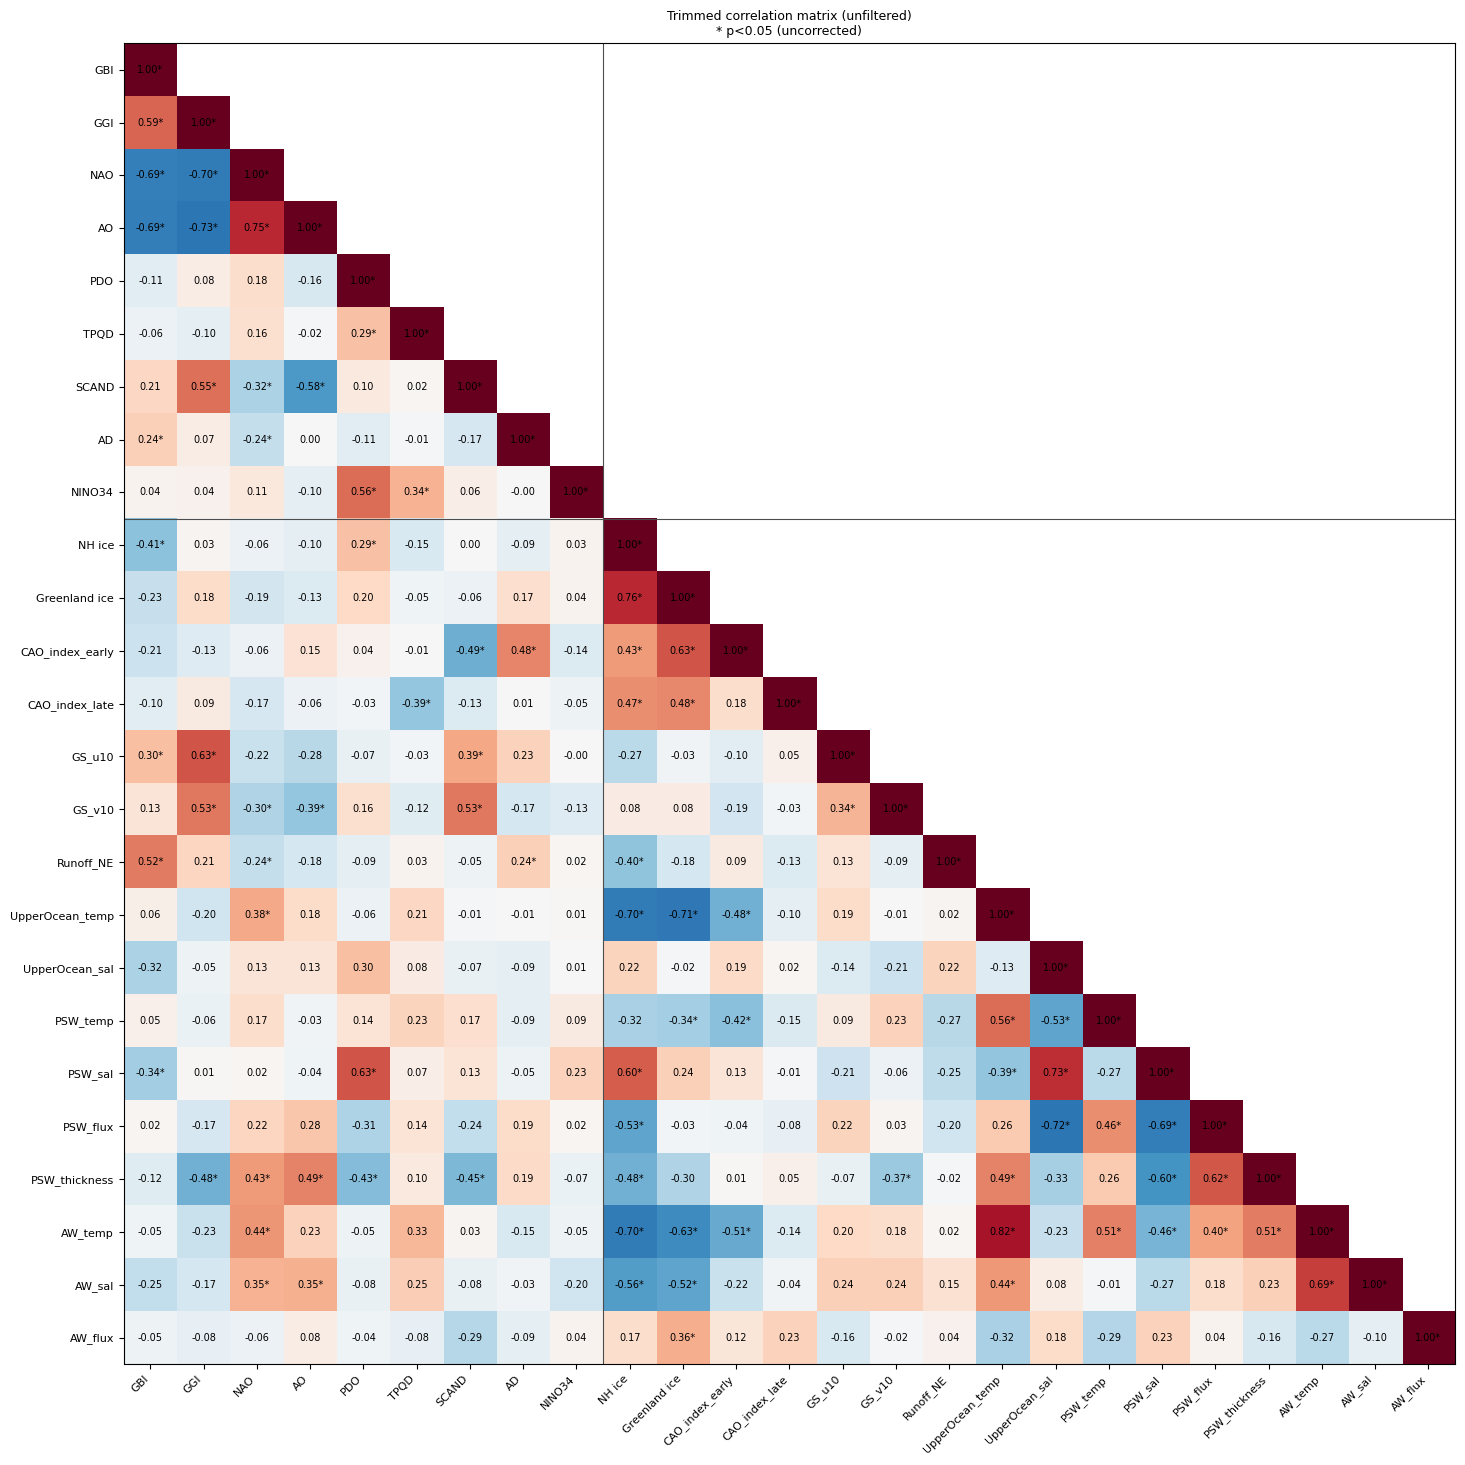

2026-10-01 10:48:34,242 | INFO    | [unfiltered] figure saved: outputs/figures/trimmed_correlation_matrix_indexONDJFMA/unfiltered/trimmed_correlation_matrix.png


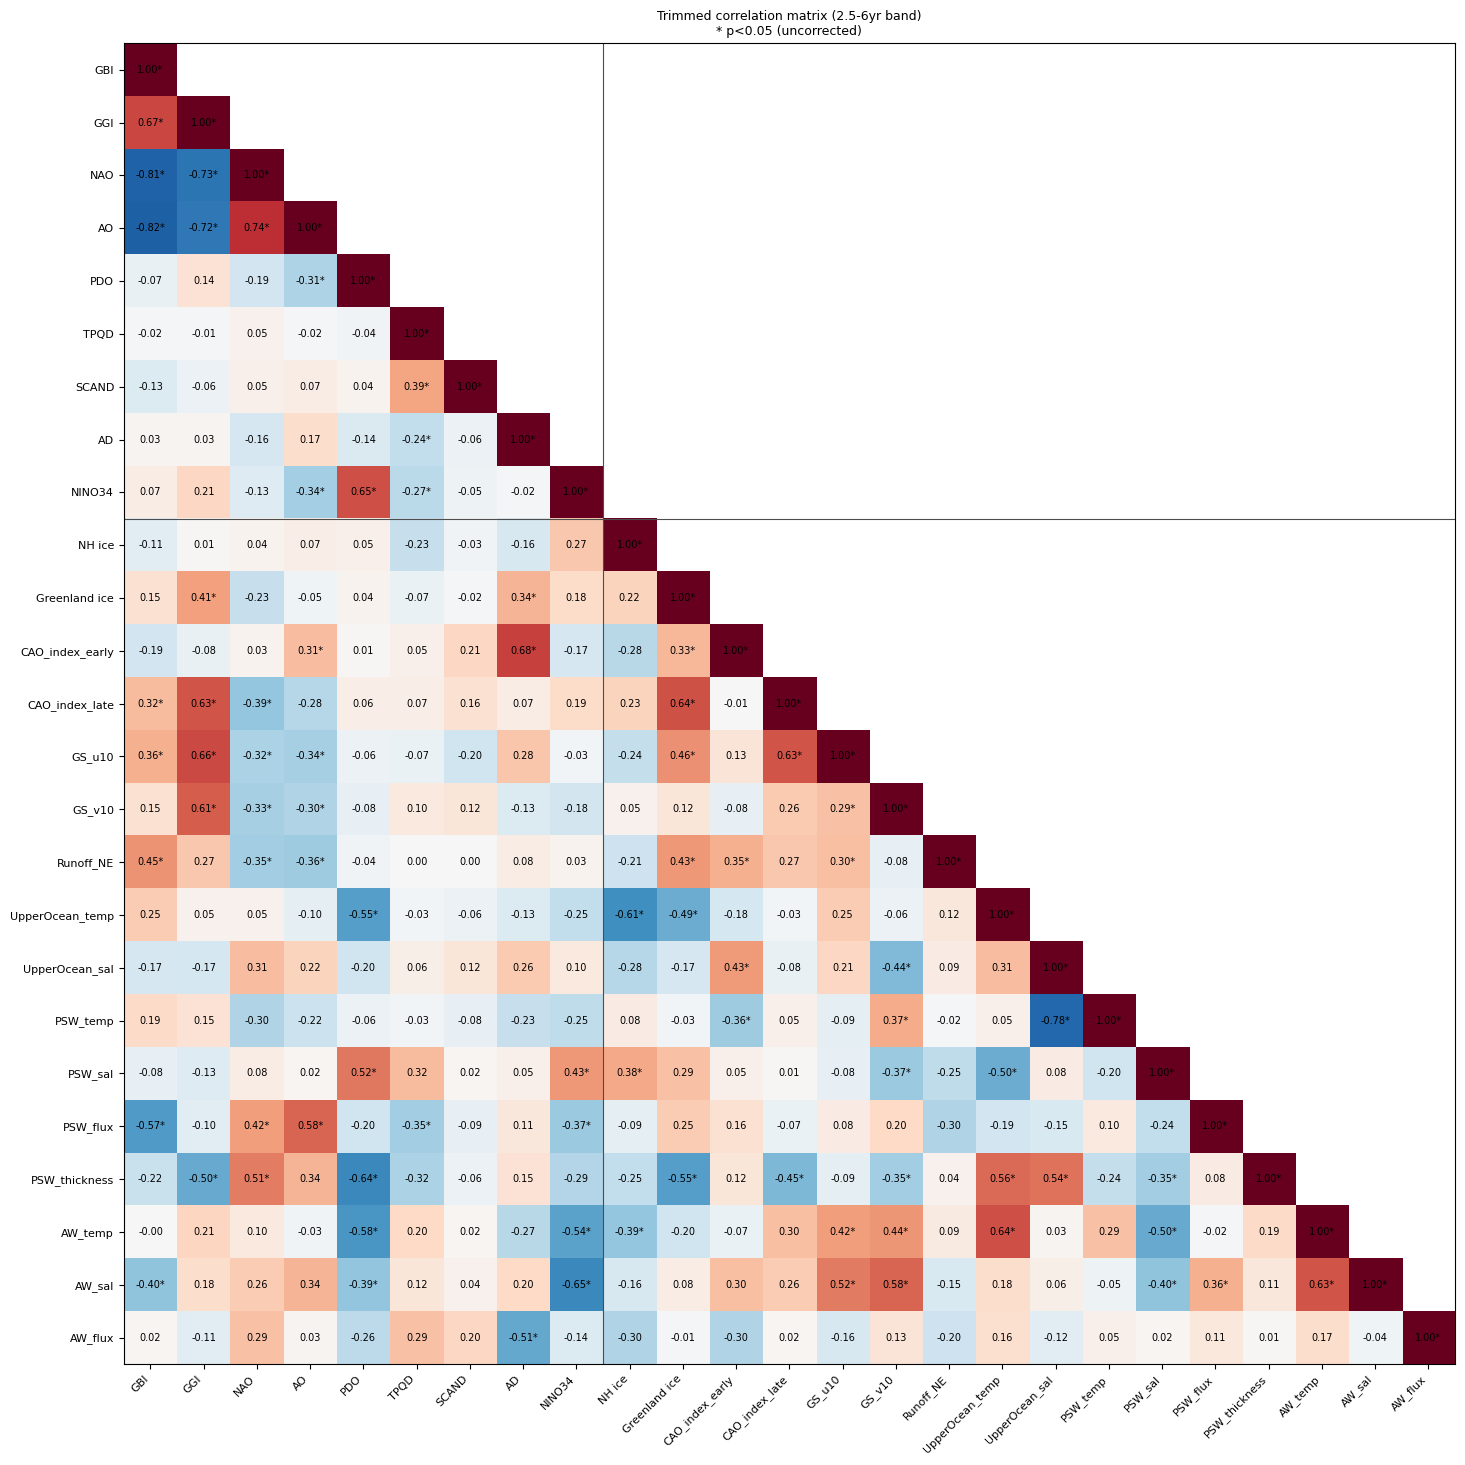

2026-10-01 10:48:49,364 | INFO    | [interannual_2.5-6yr] figure saved: outputs/figures/trimmed_correlation_matrix_indexONDJFMA/interannual_2.5-6yr/trimmed_correlation_matrix.png


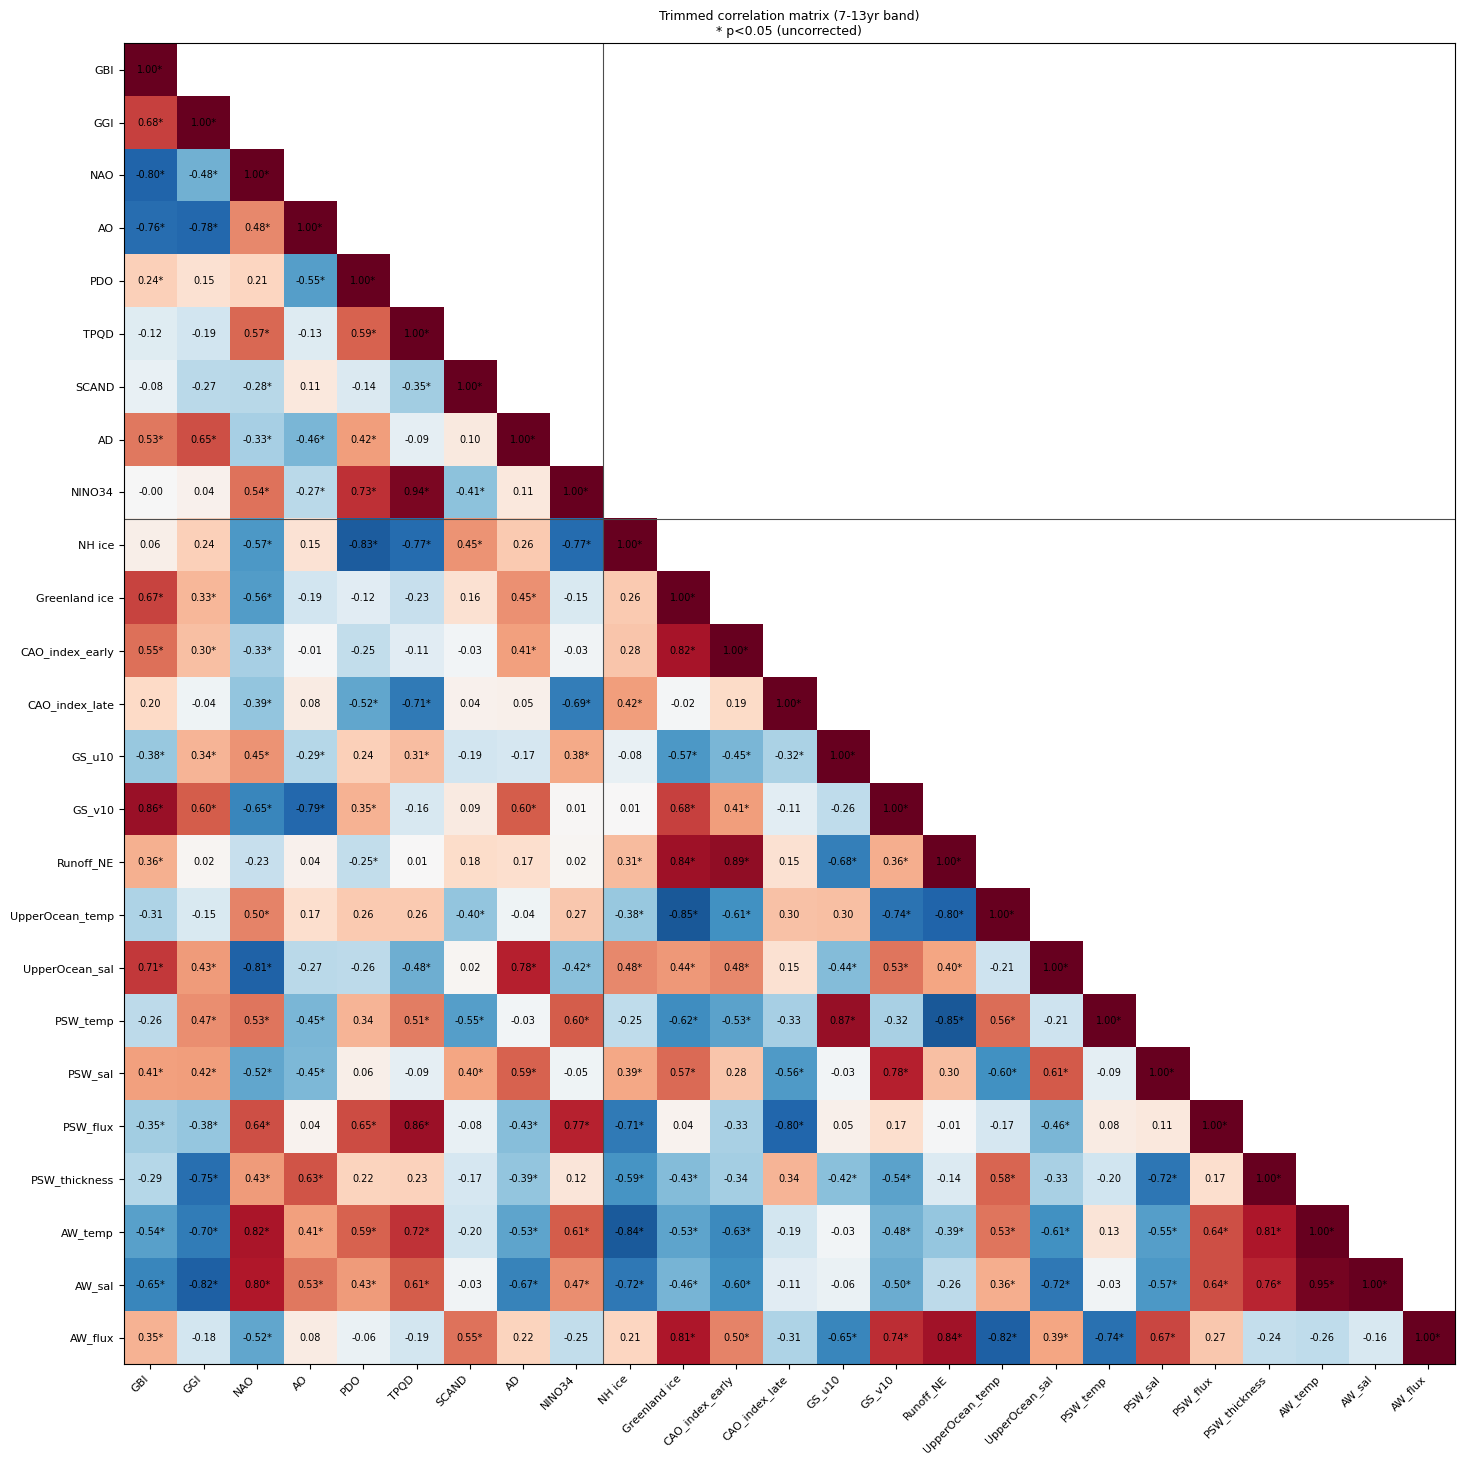

2026-10-01 10:49:05,004 | INFO    | [QD_7-13yr] figure saved: outputs/figures/trimmed_correlation_matrix_indexONDJFMA/QD_7-13yr/trimmed_correlation_matrix.png


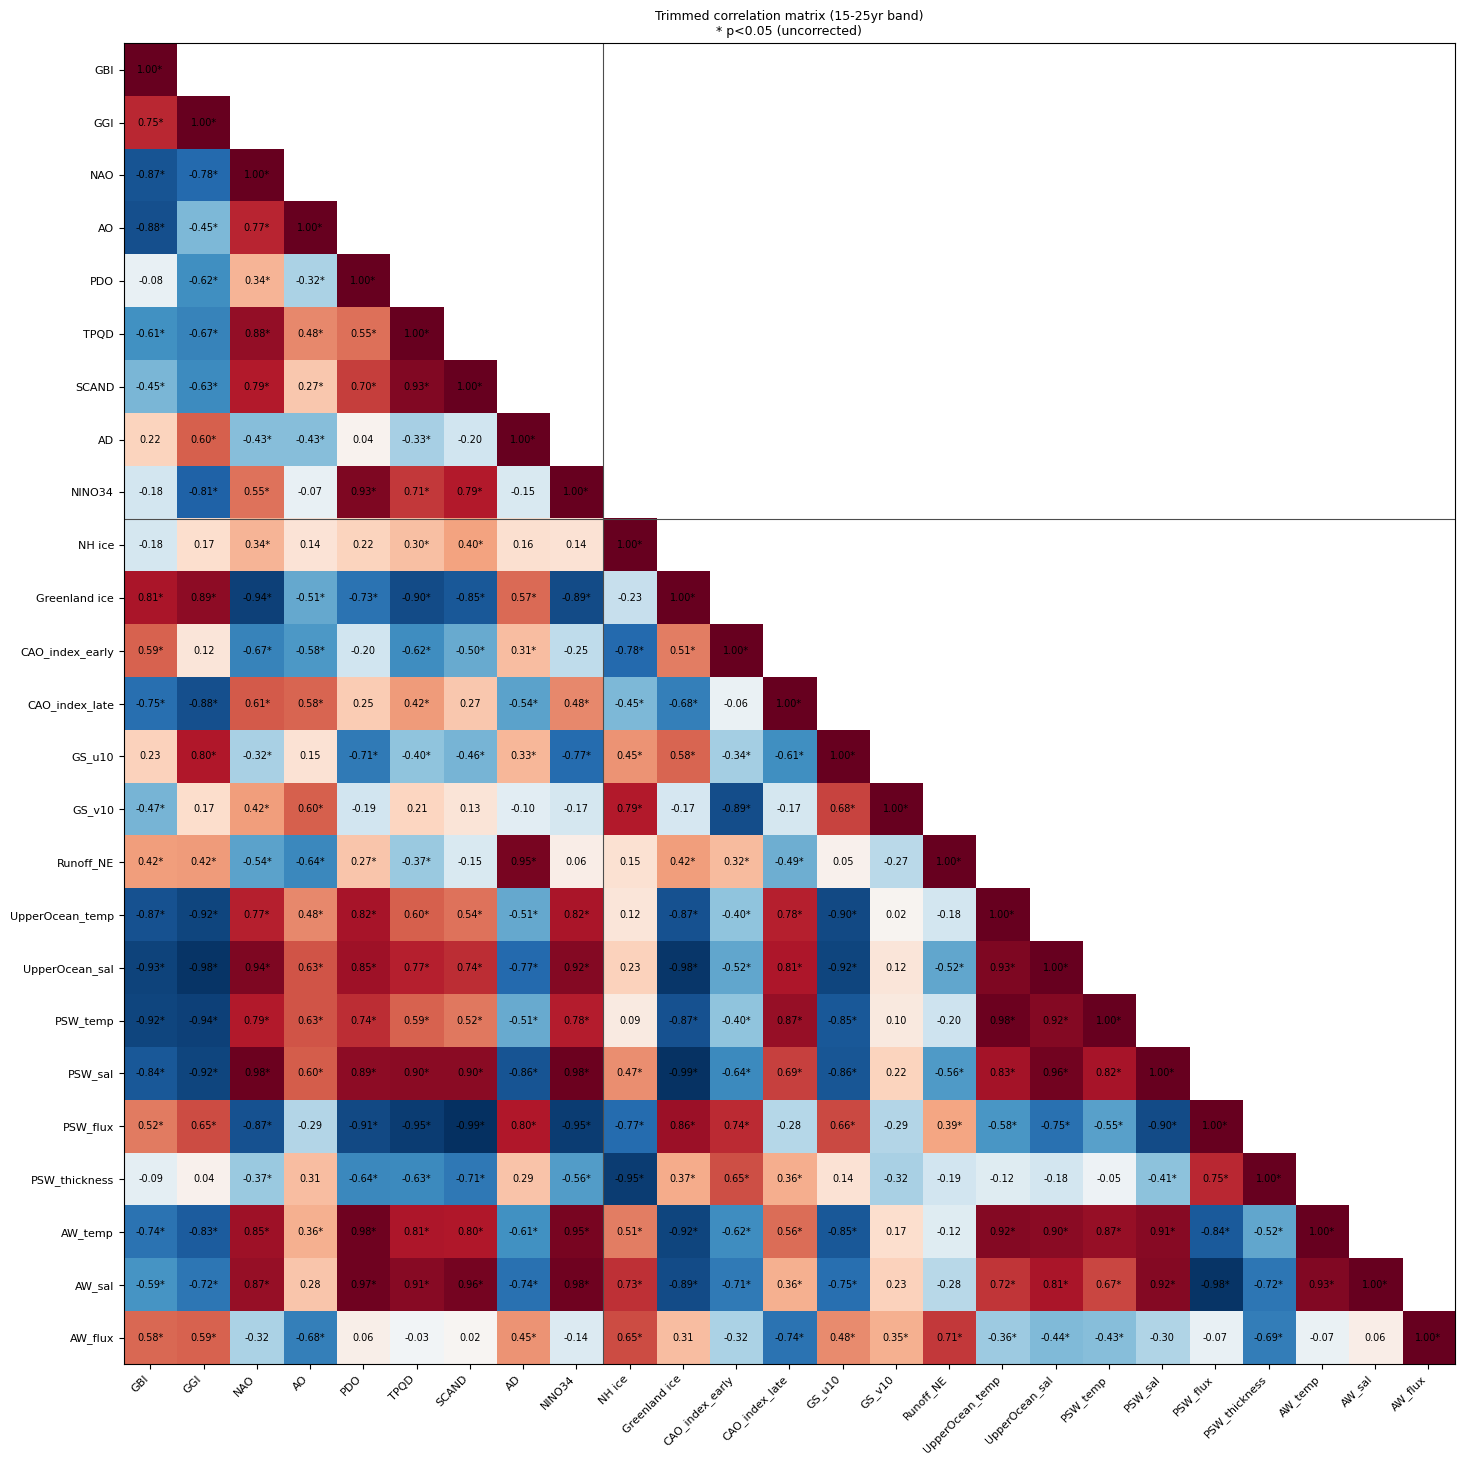

2026-10-01 10:49:20,612 | INFO    | [multidecadal_15-25yr] figure saved: outputs/figures/trimmed_correlation_matrix_indexONDJFMA/multidecadal_15-25yr/trimmed_correlation_matrix.png
2026-10-01 10:49:20,613 | INFO    | 4 figure(s) saved across 4 bands.


In [7]:
def plot_trimmed_matrix(corr, pval, names, band_tag, band_label, out_path):
    n = len(names)
    mask = np.triu(np.ones((n, n), dtype=bool), k=1)   # True = hide (upper triangle only)

    fig, ax = plt.subplots(figsize=(1 + 0.55 * n, 1 + 0.55 * n))

    display_vals = corr.values.astype(float).copy()
    display_vals[mask] = np.nan   # masked cells simply aren't drawn

    ax.imshow(display_vals, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')

    for i in range(n):
        for j in range(n):
            if mask[i, j]:
                continue
            val = corr.values[i, j]
            p = pval.values[i, j]
            if np.isfinite(val):
                marker = '*' if (np.isfinite(p) and p < ALPHA) else ''
                ax.text(j, i, f'{val:.2f}{marker}', ha='center', va='center', fontsize=7)

    labels = [dname(v) for v in names]
    ax.set_xticks(range(n)); ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(n)); ax.set_yticklabels(labels, fontsize=8)

    # Visually separate the indices block from the physical-variables block
    n_idx = len(TRIMMED_INDICES)
    ax.axhline(n_idx - 0.5, color='0.3', linewidth=0.8)
    ax.axvline(n_idx - 0.5, color='0.3', linewidth=0.8)

    ax.set_title(f'Trimmed correlation matrix ({band_label})\n* p<{ALPHA} (uncorrected)',
                fontsize=9)
    fig.tight_layout()
    fig.savefig(out_path, dpi=DPI, bbox_inches='tight')
    return fig


saved_figs = []
for band_tag, period_years in BANDS:
    corr, pval = band_matrices[band_tag]
    label = 'unfiltered' if period_years is None else f'{period_years[0]}-{period_years[1]}yr band'
    out_fig = OUT_FIG_ROOT / band_tag
    out_fig.mkdir(parents=True, exist_ok=True)
    out_path = out_fig / 'trimmed_correlation_matrix.png'
    fig = plot_trimmed_matrix(corr, pval, TRIMMED_VARS, band_tag, label, out_path)
    plt.show()
    plt.close(fig)
    saved_figs.append(out_path)
    logger.info(f"[{band_tag}] figure saved: {out_path}")

logger.info(f"{len(saved_figs)} figure(s) saved across {len(BANDS)} bands.")


## Section 5 -- Self-tests

Validated before trusting this on real data: the correlation matrix is
genuinely symmetric before masking (`corr.loc[a,b] == corr.loc[b,a]`, since
row/col use the identical variable list); the mask correctly hides exactly
the strict upper triangle and nothing else; `butterworth_bandpass_extract`
recovers a known planted periodic signal in the correct band and rejects it
outside that band.

In [8]:
def _run_self_tests():
    # --- Test 1: matrix symmetry (same var list on both axes) ---
    _rng = np.random.default_rng(0)
    _names = ['A', 'B', 'C', 'D']
    _years = np.arange(1980, 2026)
    _sd = {n: pd.Series(_rng.normal(size=len(_years)), index=_years) for n in _names}
    _corr, _pval = build_correlation_matrix(_names, _sd)
    for a, b in product(_names, _names):
        assert np.isclose(_corr.loc[a, b], _corr.loc[b, a], equal_nan=True), \
            f"Test 1 FAILED: matrix not symmetric at ({a},{b})"
    print("PASS: correlation matrix is symmetric (same variable list on both axes).")

    # --- Test 2: masking hides exactly the strict upper triangle ---
    _n = len(_names)
    _mask = np.triu(np.ones((_n, _n), dtype=bool), k=1)
    assert _mask[0, 1] and _mask[0, 3] and not _mask[1, 0] and not _mask[3, 0], \
        "Test 2 FAILED: mask orientation wrong"
    assert not _mask[0, 0] and not _mask[2, 2], "Test 2 FAILED: diagonal should stay visible"
    print("PASS: mask hides exactly the strict upper triangle, diagonal stays visible.")

    # --- Test 3: Butterworth recovers a planted signal in-band, rejects out-of-band ---
    _t = np.arange(60)
    _period_true = 10.0
    _signal = np.sin(2 * np.pi * _t / _period_true)
    _noise = _rng.normal(scale=0.05, size=60)
    _y = _signal + _noise

    _in_band = butterworth_bandpass_extract(_y, 7, 13)
    _r_in, _ = stats.pearsonr(_in_band, _signal)
    assert abs(_r_in) > 0.9, f"Test 3a FAILED: expected strong recovery in-band, got r={_r_in:.2f}"
    print(f"PASS: 7-13yr filter recovers a planted 10yr signal (r={_r_in:.2f} vs input).")

    _out_band = butterworth_bandpass_extract(_y, 15, 25)
    _power_out = np.var(_out_band)
    _power_in = np.var(_in_band)
    assert _power_out < 0.3 * _power_in, \
        f"Test 3b FAILED: 15-25yr filter should suppress a 10yr signal much more than " \
        f"the 7-13yr filter does (power_out={_power_out:.4f}, power_in={_power_in:.4f})"
    print(f"PASS: 15-25yr filter correctly suppresses the same 10yr signal "
         f"(variance ratio out/in = {_power_out/_power_in:.3f}).")

    print()
    print("ALL SELF-TESTS PASSED.")


_run_self_tests()


PASS: correlation matrix is symmetric (same variable list on both axes).
PASS: mask hides exactly the strict upper triangle, diagonal stays visible.
PASS: 7-13yr filter recovers a planted 10yr signal (r=0.96 vs input).
PASS: 15-25yr filter correctly suppresses the same 10yr signal (variance ratio out/in = 0.029).

ALL SELF-TESTS PASSED.


In [9]:
def _run_corrected_p_self_tests():
    _rng = np.random.default_rng(1)

    # Test 4: surrogates preserve the amplitude spectrum and mean exactly
    for _n in (47, 48):   # odd and even lengths (Nyquist handling)
        _y = np.cumsum(_rng.normal(size=_n))
        _s = ebisuzaki_surrogates(_y, 50, _rng)
        assert np.allclose(np.abs(np.fft.rfft(_s, axis=1)),
                           np.abs(np.fft.rfft(_y))[None, :]), f"Test 4 FAILED (n={_n}): spectrum changed"
        assert np.allclose(_s.mean(axis=1), _y.mean()), f"Test 4 FAILED (n={_n}): mean changed"
        assert np.isrealobj(_s)
    print("PASS: Ebisuzaki surrogates preserve the amplitude spectrum and mean (odd and even n).")

    # Test 5: N_eff ~ N for long independent white noise
    _x, _z = _rng.normal(size=2000), _rng.normal(size=2000)
    _ne = effective_n(_x, _z)
    assert 0.85 * 2000 < _ne <= 2000, f"Test 5 FAILED: white-noise N_eff={_ne:.0f}, expected ~2000"
    print(f"PASS: N_eff ~ N for independent white noise (N_eff={_ne:.0f}, N=2000).")

    # Test 6: N_eff << N after 7-13yr band-pass of 47 annual values
    _xf = butterworth_bandpass_extract(_rng.normal(size=47), 7, 13)
    _zf = butterworth_bandpass_extract(_rng.normal(size=47), 7, 13)
    _ne_f = effective_n(_xf, _zf)
    assert _ne_f < 0.5 * 47, f"Test 6 FAILED: band-passed N_eff={_ne_f:.1f}, expected << 47"
    print(f"PASS: N_eff strongly reduced after 7-13yr band-pass (N_eff={_ne_f:.1f}, N=47).")

    # Test 7: with N_eff = N, p_from_neff reproduces scipy's plain Pearson p
    _a, _b = _rng.normal(size=40), _rng.normal(size=40)
    _r, _p = stats.pearsonr(_a, _b)
    assert np.isclose(p_from_neff(_r, 40.0), _p), "Test 7 FAILED: p_from_neff(N) != pearsonr p"
    print("PASS: p_from_neff with N_eff = N reproduces plain Pearson p.")

    # Test 8: saved corrected matrices are symmetric and their non-NaN cells match the r matrix
    if COMPUTE_CORRECTED_P:
        for _bt, (_pn, _nef, _ps) in corrected_matrices.items():
            for _m in (_pn, _nef, _ps):
                assert np.allclose(_m.values, _m.values.T, equal_nan=True), f"Test 8 FAILED: [{_bt}] not symmetric"
            _corr = band_matrices[_bt][0]
            assert (_pn.notna() == _corr.notna()).all().all(), f"Test 8 FAILED: [{_bt}] N_eff p coverage != r coverage"
        print("PASS: corrected p-value matrices are symmetric and cover exactly the r cells.")

    print()
    print("ALL CORRECTED-P SELF-TESTS PASSED.")


_run_corrected_p_self_tests()


PASS: Ebisuzaki surrogates preserve the amplitude spectrum and mean (odd and even n).
PASS: N_eff ~ N for independent white noise (N_eff=2000, N=2000).
PASS: N_eff strongly reduced after 7-13yr band-pass (N_eff=6.6, N=47).
PASS: p_from_neff with N_eff = N reproduces plain Pearson p.
PASS: corrected p-value matrices are symmetric and cover exactly the r cells.

ALL CORRECTED-P SELF-TESTS PASSED.


## Section 6 -- Methodology documentation

In [10]:
def write_methodology():
    band_list_txt = "\n".join(
        f"  - {tag}: {'unfiltered' if py is None else f'{py[0]}-{py[1]}yr'}" for tag, py in BANDS)
    txt = f"""# Trimmed Correlation Matrix

Trimmed, masked version of Fig 2 from cross_comparison_sea_ice_climate_indices.ipynb
(source of correlation_matrix_added_vars_10yr_alt.png), restricted to a curated
variable list, across the same four bands used in compute_spatial_correlations.ipynb.

## Bands
{band_list_txt}

## Variables (same ordered list on both axes -- square matrix)

Indices: {', '.join(TRIMMED_INDICES)}
Physical: {', '.join(TRIMMED_PHYSICAL)}

## Method

Data loading, ICE_METRIC='annual_max' from daily OSISAF data, and the
Butterworth band-pass filter (order 4, reflection-padded) are all reused
directly from cross_comparison_sea_ice_climate_indices.ipynb, not
re-derived. GGI (compute_ggi_index.ipynb) is the one new addition, loaded
the same way as every other single-CSV variable.

## Season convention

Ocean variables (PSW/AW flux, upper-ocean T/S, runoff, GS winds) and GGI
always use CLIM_WINTER_MONTHS={CLIM_WINTER_MONTHS} (Dec-Mar) -- DIFFERENT
from this project's usual WINTER_MONTHS=[10..4], matched here specifically
to keep these numbers comparable to the original matrix.

Climate indices (GBI, NAO, AO, PDO, TPQD, SCAND, NINO3.4 -- NOT GGI, which
shares the ocean variables' code path) use INDEX_WINTER_MONTHS instead,
set by INDEX_SEASON='{INDEX_SEASON}': {INDEX_WINTER_MONTHS}. This run used
the {'original DJFM convention, matching the ocean variables' if INDEX_SEASON == 'DJFM' else 'full ONDJFMA winter, for consistency with the unfiltered-monthly panel -- NOT the same convention as the ocean variables in this same matrix, which remain on DJFM'}.
{'' if INDEX_SEASON == 'DJFM' else f"Output written to a separate directory ({OUT_FIG_ROOT.name}) rather than overwriting the DJFM-based matrix."}

Statistical method matches the source notebook's Fig 2 exactly: plain
Pearson r/p (scipy.stats.pearsonr), minimum 8 overlapping points and
nonzero variance in both series required, `*` marks p<{ALPHA} (uncorrected --
no FDR here, to stay consistent with what's already in the original image;
compute_eof_correlation_timescales.ipynb's Ebisuzaki-surrogate + FDR
approach was NOT used, since that's specific to that notebook's own EOF
work, not this matrix's established methodology).

## Display

Upper triangle masked (diagonal visible) since the matrix is symmetric
(same variable list on both axes) -- every masked value is a mirror-image
repeat of a visible one. Colorbar dropped; values are annotated in each
cell. A dividing line separates the indices block from the physical-
variables block.

## Data vs. display

The saved CSV tables (`correlation_matrix.csv`, `correlation_pvalues.csv`,
per band) contain the FULL matrix, including the upper triangle -- masking
is a display-only choice made at the plotting step, never applied to the
saved data.
"""
    p = OUT_METH / 'trimmed_correlation_matrix_methodology.md'
    p.write_text(txt)
    logger.info(f"Methodology written: {p}")


write_methodology()


2026-10-01 10:49:20,736 | INFO    | Methodology written: outputs/methods/trimmed_correlation_matrix_methodology.md


In [11]:
def write_corrected_p_methodology():
    """Separate methods file for the 1.4.0 corrected p-values, plus a
    comparison CSV of plain / N_eff / surrogate p for the index x
    SUMMARY_TARGETS cells (Figure 8 panel (a)), all bands."""
    if not COMPUTE_CORRECTED_P:
        logger.info('COMPUTE_CORRECTED_P=False -- corrected-p methodology not written.')
        return
    rows = []
    for band_tag, _ in BANDS:
        corr, pval = band_matrices[band_tag]
        p_neff, n_eff_df, p_surr = corrected_matrices[band_tag]
        for idx in TRIMMED_INDICES:
            for tgt in SUMMARY_TARGETS:
                if idx not in corr.index or tgt not in corr.columns:
                    continue
                if not np.isfinite(corr.loc[idx, tgt]):
                    continue
                rows.append(dict(band=band_tag, index=idx, target=tgt,
                                 r=corr.loc[idx, tgt], p_plain=pval.loc[idx, tgt],
                                 n_eff=n_eff_df.loc[idx, tgt], p_neff=p_neff.loc[idx, tgt],
                                 p_surrogate=p_surr.loc[idx, tgt]))
    comp = pd.DataFrame(rows)
    if SAVE_DATA:
        comp.to_csv(OUT_DATA_ROOT / 'corrected_pvalue_comparison.csv', index=False)

    summary_lines = []
    for band_tag, _ in BANDS:
        c = comp[comp.band == band_tag]
        if c.empty:
            continue
        summary_lines.append(
            f"| {band_tag} | {c.n_eff.min():.1f}-{c.n_eff.max():.1f} (median {c.n_eff.median():.1f}) "
            f"| {int((c.p_plain < ALPHA).sum())} | {int((c.p_neff < ALPHA).sum())} "
            f"| {int((c.p_surrogate < ALPHA).sum())} | {len(c)} |")
    lost = comp[(comp.p_plain < ALPHA) & ((comp.p_neff >= ALPHA) | (comp.p_surrogate >= ALPHA))]
    lost_lines = [f"- {r.band}: {r.index} vs {r.target} (r = {r.r:+.2f}; p plain {r.p_plain:.3f}, "
                  f"N_eff {r.n_eff:.1f} -> p {r.p_neff:.3f}, surrogate p {r.p_surrogate:.3f})"
                  for r in lost.itertuples()]

    txt = f"""# Trimmed Correlation Matrix: autocorrelation-corrected significance (v1.4.0)

## Why
Plain Pearson p-values (correlation_pvalues.csv) assume independent
samples. Annual climate series are autocorrelated, and band-pass filtering
greatly increases this: at annual resolution the 7-13yr band of a ~47-year
overlap contains only ~4-6 independent cycles. Plain p-values are therefore
too small, most severely in the filtered bands. The r values are unchanged;
only significance is recomputed.

## Methods
Same pairs, same overlap rule (inner join of the two (filtered) series,
NaNs dropped, >= 8 points, nonzero variance) as the plain matrix; r is
recomputed and asserted identical to correlation_matrix.csv.

1. Effective sample size (correlation_pvalues_neff.csv, effective_n.csv).
   N_eff = N / (1 + 2 sum_{{k=1..K}} rho_x(k) rho_y(k)) (Bartlett 1935;
   Bretherton et al. 1999), summed over all lags up to
   K = floor({NEFF_MAX_LAG_FRAC} x N) using biased (1/N-normalised)
   autocorrelation estimates of the two series over their overlap, clipped
   to [{NEFF_MIN}, N]. Two-sided t-test with N_eff - 2 degrees of freedom.
   The full-lag form is used, not the lag-1 (AR(1)) approximation, because
   band-passed series are oscillatory and a lag-1 estimate understates their
   memory.

2. Phase-randomised surrogates (correlation_pvalues_surrogate.csv).
   Ebisuzaki (1997): {N_SURROGATES} surrogates per variable per band, each
   with the RAW series' Fourier amplitude spectrum and mean but random
   phases. Each surrogate is passed through the identical Butterworth
   band-pass filter (order {BUTTER_ORDER}, reflection-padded) as the real
   data, then correlated with the other (real, filtered) series over the
   same overlap years. p = (number of |r_surr| >= |r_obs| + 1) / ({N_SURROGATES} + 1),
   two-sided; minimum attainable p = {1 / (N_SURROGATES + 1):.4f}. For each
   pair the variable earlier in TRIMMED_VARS is randomised -- i.e. the
   climate index for every index-vs-physical cell. Seeded by
   (SURROGATE_SEED={SURROGATE_SEED}, band, variable position).
   Because the filter is applied to each surrogate, this test accounts for
   the filter (including edge/padding effects) exactly and is the more
   defensible of the two for the filtered bands.

Synthetic check during development (independent AR(1), phi = 0.6, 144
index-physical pairs, nominal 5%): false-positive rates were plain
14/22/56/81%, N_eff 4/4/8/24%, surrogate 5/6/7/7% for the
unfiltered/2.5-6/7-13/15-25yr bands. N_eff is adequate up to 7-13yr but
remains anti-conservative at 15-25yr; the surrogate test holds its nominal
rate in all bands.

## Index x {{{', '.join(SUMMARY_TARGETS)}}} cells (Figure 8 panel (a))

| Band | N_eff range | plain p<{ALPHA} | N_eff p<{ALPHA} | surrogate p<{ALPHA} | cells |
|---|---|---|---|---|---|
{chr(10).join(summary_lines)}

Cells significant under plain p but not under at least one correction:
{chr(10).join(lost_lines) if lost_lines else '- none'}

Full values: corrected_pvalue_comparison.csv in {OUT_DATA_ROOT}.

## Files
Per band, alongside the unchanged originals (correlation_matrix.csv,
correlation_pvalues.csv): correlation_pvalues_neff.csv, effective_n.csv,
correlation_pvalues_surrogate.csv. Full square matrices, symmetric.
Output root: {OUT_DATA_ROOT} (INDEX_SEASON={INDEX_SEASON!r}).
"""
    p = OUT_METH / 'trimmed_correlation_matrix_corrected_pvalues_methodology.md'
    p.write_text(txt)
    logger.info(f"Corrected-p methodology written: {p}")
    print(txt)


write_corrected_p_methodology()


2026-10-01 10:49:20,791 | INFO    | Corrected-p methodology written: outputs/methods/trimmed_correlation_matrix_corrected_pvalues_methodology.md


# Trimmed Correlation Matrix: autocorrelation-corrected significance (v1.4.0)

## Why
Plain Pearson p-values (correlation_pvalues.csv) assume independent
samples. Annual climate series are autocorrelated, and band-pass filtering
greatly increases this: at annual resolution the 7-13yr band of a ~47-year
overlap contains only ~4-6 independent cycles. Plain p-values are therefore
too small, most severely in the filtered bands. The r values are unchanged;
only significance is recomputed.

## Methods
Same pairs, same overlap rule (inner join of the two (filtered) series,
NaNs dropped, >= 8 points, nonzero variance) as the plain matrix; r is
recomputed and asserted identical to correlation_matrix.csv.

1. Effective sample size (correlation_pvalues_neff.csv, effective_n.csv).
   N_eff = N / (1 + 2 sum_{k=1..K} rho_x(k) rho_y(k)) (Bartlett 1935;
   Bretherton et al. 1999), summed over all lags up to
   K = floor(0.25 x N) using biased (1/N-normalised)
   autocorrelation estimates of the two se